In [2]:
import cv2 
import tensorflow as tf
import os
import numpy as np 


data_dir = '/kaggle/input/datasets/mohamedafkir90/tomato-quality-classification/Tomato_dataset'
    
valid_extensions = ['.jpeg', '.jpg', '.png' ,'bmp']

#test function
def is_valid_image(file_path):
    # 1. Check if the file extension is correct
    ext = os.path.splitext(file_path)[1].lower()
    if ext not in valid_extensions:
        return False
        
    # try opening the image with OpenCV
    img = cv2.imread(file_path)
    if img is None:
        return False
        
    return True

2026-05-04 11:03:11.326590: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777892591.507977      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777892591.558949      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777892591.986061      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777892591.986102      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777892591.986105      57 computation_placer.cc:177] computation placer alr

In [3]:
os.listdir(data_dir)

['Local', 'Export', 'Rotten']

In [4]:
#remove the bad images
for dir1 in os.listdir(data_dir):
    # print(dir1)
    for img in os.listdir(os.path.join(data_dir,dir1 )):
        full_img_path = os.path.join(data_dir, dir1,  img)
        if not is_valid_image(full_img_path):
            os.remove(full_img_path)

In [13]:
import splitfolders
from matplotlib import pyplot as plt

In [14]:
input_folder = '/kaggle/input/datasets/mohamedafkir90/tomato-quality-classification/Tomato_dataset'
output_folder = '/kaggle/working/tomato_split' # Save to the writable directory

splitfolders.ratio(input_folder, 
                   output=output_folder, 
                   seed=42, 
                   ratio=(.8, .1, .1), # (train, val, test)
                   group_prefix=None, 
                   move=False) # Use False to copy files

Copying files: 8000 files [00:17, 458.17 files/s]


In [17]:
BATCH_SIZE = 32
IMG_SIZE = (224, 224) 

train_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/val',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/test',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
class_names = train_ds.class_names
print("\n classes are:", class_names)

Found 6400 files belonging to 3 classes.
Found 800 files belonging to 3 classes.
Found 800 files belonging to 3 classes.

 classes are: ['Export', 'Local', 'Rotten']


In [18]:
data_iterator = train_ds.as_numpy_iterator()

In [19]:
data_iterator

NumpyIterator(iterator=<tensorflow.python.data.ops.iterator_ops.OwnedIterator object at 0x7d6ec9abfdd0>)

In [20]:
batch = data_iterator.next()

In [21]:
batch[1]

array([1, 1, 1, 1, 2, 1, 1, 2, 1, 2, 2, 2, 1, 1, 0, 2, 1, 0, 2, 1, 1, 2,
       1, 1, 1, 2, 1, 1, 2, 0, 1, 0], dtype=int32)

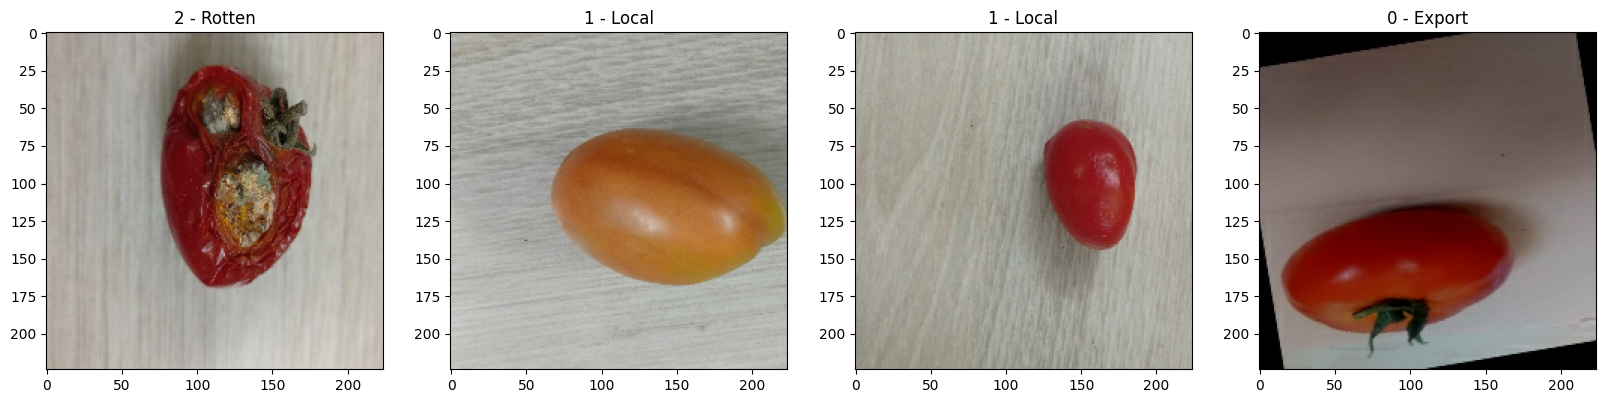

In [27]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))

start_idx = 11

for i in range(4):
    true_idx = start_idx + i 
    
    img = batch[0][true_idx]
    label_id = batch[1][true_idx]
    
    ax[i].imshow(img.astype(int))
    ax[i].title.set_text(f"{label_id} - {class_names[label_id]}")

#### Class 0: Export
#### Class 1: Local
#### Class 2: Rotten

In [28]:
Train_data = train_ds.map(lambda x,y: (x/255,y))

Val_data = val_ds.map(lambda x,y: (x/255,y))

Test_data = test_ds.map(lambda x,y: (x/255,y))

In [29]:
batch[0].max()

np.float32(255.0)

In [30]:
#scaled data min=0 and max = 1
scaled_batch = Train_data.as_numpy_iterator().next()
scaled_batch[0].max()

np.float32(1.0)

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense,GlobalAveragePooling2D, Flatten, Dropout

In [56]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Pour supprime le model precedent
tf.keras.backend.clear_session() 


model = Sequential([
    
    Input(shape=(224, 224, 3)),
    
    Conv2D(16, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Dropout(0.4),
    
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    
    Conv2D(16, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Dropout(0.4),
    
    Flatten(),
    
    Dense(256, activation='relu'),
    Dropout(0.5),
    
    Dense(3, activation='softmax')
])


model.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 26, 26, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,769,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,779,635 (10.60 MB)

 Trainable params: 2,779,635 (10.60 MB)

 Non-trainable params: 0 (0.00 B)

In [57]:
log_dir = "/kaggle/working/logs"
os.makedirs(log_dir, exist_ok=True)

In [58]:
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir)

In [59]:
hist =model.fit(Train_data, epochs=20 , validation_data=Val_data ,callbacks=[tensorboard_callback])

Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 88s 410ms/step - accuracy: 0.4878 - loss: 1.0131 - val_accuracy: 0.7412 - val_loss: 0.6023
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 84s 421ms/step - accuracy: 0.7470 - loss: 0.5870 - val_accuracy: 0.6538 - val_loss: 0.8595
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 84s 421ms/step - accuracy: 0.8214 - loss: 0.4398 - val_accuracy: 0.8800 - val_loss: 0.3375
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 84s 420ms/step - accuracy: 0.8551 - loss: 0.3389 - val_accuracy: 0.8125 - val_loss: 0.4534
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 84s 419ms/step - accuracy: 0.8828 - loss: 0.2923 - val_accuracy: 0.8788 - val_loss: 0.3348
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 84s 420ms/step - accuracy: 0.9195 - loss: 0.2259 - val_accuracy: 0.8963 - val_loss: 0.2965
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 85s 423ms/step - accuracy: 0.9301 - loss: 0.1891 - val_accuracy: 0.9038 - val_loss: 0.2791
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 84s 422ms/step - accuracy: 0.9333 - loss: 0

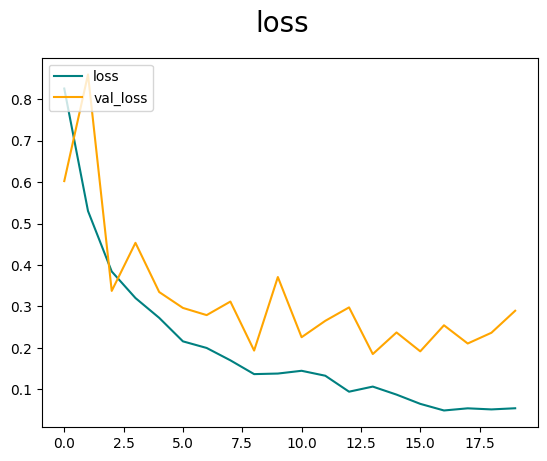

In [60]:
fig = plt.figure
plt.plot(hist.history['loss'],color='teal', label='loss')
plt.plot(hist.history['val_loss'],color='orange', label='val_loss')
plt.suptitle('loss',fontsize=20)
plt.legend(loc='upper left')
plt.show()

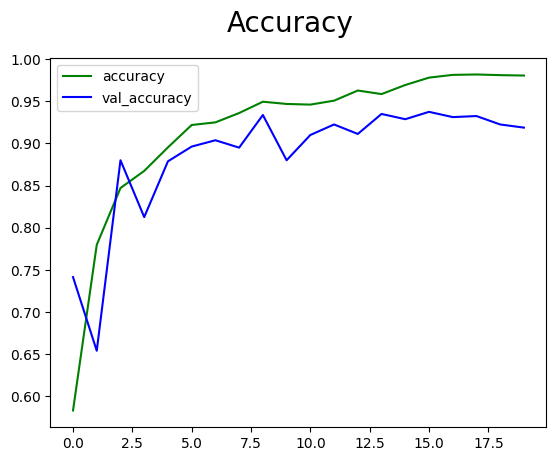

In [61]:
fig = plt.figure
plt.plot(hist.history['accuracy'],color='green', label='accuracy')
plt.plot(hist.history['val_accuracy'],color='blue', label='val_accuracy')
plt.suptitle('Accuracy',fontsize=20)
plt.legend(loc='upper left')
plt.show()

In [67]:
from sklearn.metrics import classification_report, confusion_matrix

y_true_all = []
y_pred_all = []


for batch in Test_data.as_numpy_iterator():
    X, y = batch
    
    
    y_predict_probs = model.predict(X, verbose=0)
    
    
    y_predict_classes = np.argmax(y_predict_probs, axis=1)
    
    
    y_true_all.extend(y)
    y_pred_all.extend(y_predict_classes)


print("Classification Report:")
print(classification_report(y_true_all, y_pred_all, target_names=['Local', 'Export', 'Rotten']))

Classification Report:
              precision    recall  f1-score   support

       Local       0.98      0.93      0.95       200
      Export       0.94      0.79      0.86       300
      Rotten       0.82      0.98      0.90       300

    accuracy                           0.90       800
   macro avg       0.91      0.90      0.90       800
weighted avg       0.91      0.90      0.90       800



In [79]:
models_dir = "/kaggle/working/models"
os.makedirs(models_dir, exist_ok=True)

In [95]:
from tensorflow.keras.models import load_model
# save the model 
model.save(os.path.join(models_dir,'Tomato_grading_01.keras'))